In [4]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\Admin\TUBES_IPSD_1-1\dataset")
print(DATA_DIR.exists())                      # harus True
print([p.name for p in DATA_DIR.iterdir()])   # harus ada train, valid, test

True
['moths-99.60.h5', 'MOTHS.csv', 'test', 'train', 'valid']


In [5]:
import os, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

random.seed(42)
sns.set_theme(style="whitegrid")
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
SAMPLE_PER_CLASS = 30

In [6]:
rows = []
for split in ["train", "valid", "test"]:
    for cls_dir in sorted((DATA_DIR / split).iterdir()):
        if cls_dir.is_dir():
            for f in cls_dir.iterdir():
                if f.suffix.lower() in EXTS:
                    rows.append({"split": split, "kelas": cls_dir.name, "path": str(f)})

df = pd.DataFrame(rows)
print(f"Total gambar: {len(df)} | Jumlah kelas: {df['kelas'].nunique()}")
print(df["split"].value_counts())
df.head()

Total gambar: 7683 | Jumlah kelas: 50
split
train    7183
valid     250
test      250
Name: count, dtype: int64


,split,kelas,path
0,train,ARCIGERA FLOWER MOTH,C:\Users\Admin\TUBES_IPSD_1-1\dataset\train\AR...
1,train,ARCIGERA FLOWER MOTH,C:\Users\Admin\TUBES_IPSD_1-1\dataset\train\AR...
2,train,ARCIGERA FLOWER MOTH,C:\Users\Admin\TUBES_IPSD_1-1\dataset\train\AR...
3,train,ARCIGERA FLOWER MOTH,C:\Users\Admin\TUBES_IPSD_1-1\dataset\train\AR...
4,train,ARCIGERA FLOWER MOTH,C:\Users\Admin\TUBES_IPSD_1-1\dataset\train\AR...


count     50.000000
mean     153.660000
std       21.792725
min      111.000000
25%      139.250000
50%      150.500000
75%      175.000000
max      196.000000
Name: count, dtype: float64
Rasio imbalance (max/min): 1.77


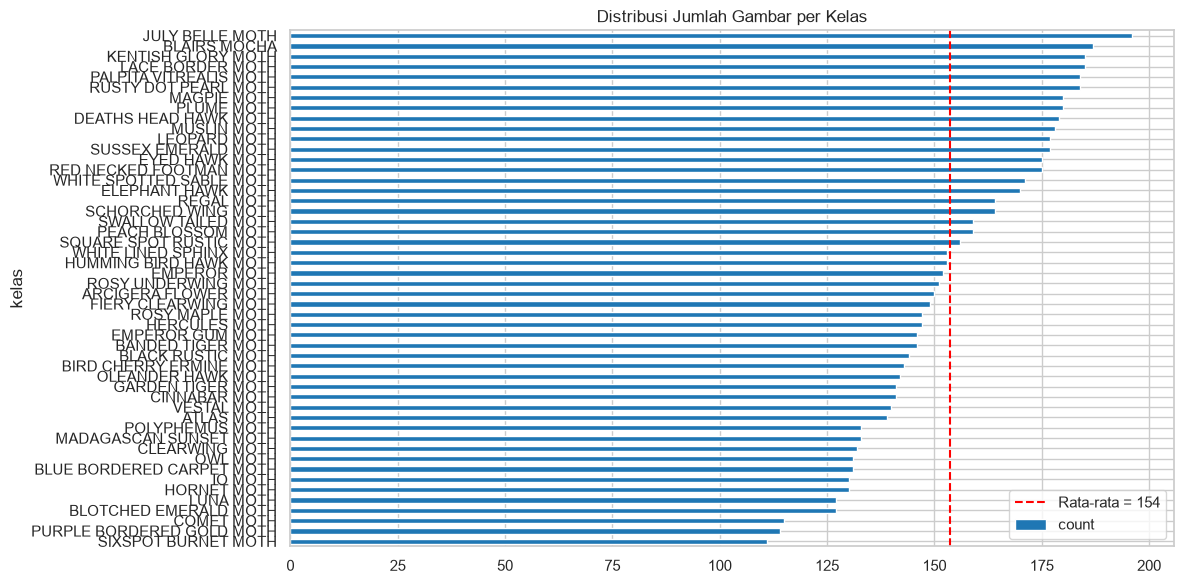

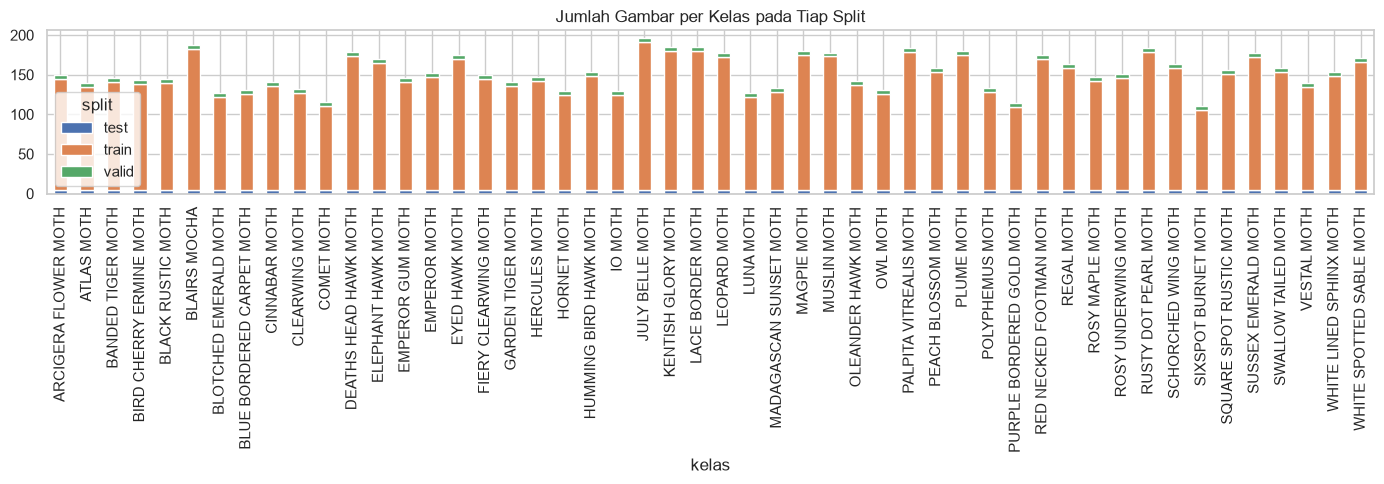

In [7]:
counts = df["kelas"].value_counts()
print(counts.describe())
print(f"Rasio imbalance (max/min): {counts.max()/counts.min():.2f}")

plt.figure(figsize=(12, 6))
counts.sort_values().plot(kind="barh", color="#1f77b4")
plt.axvline(counts.mean(), color="red", ls="--", label=f"Rata-rata = {counts.mean():.0f}")
plt.title("Distribusi Jumlah Gambar per Kelas")
plt.legend(); plt.tight_layout(); plt.show()

pd.crosstab(df["kelas"], df["split"]).plot(kind="bar", stacked=True, figsize=(14, 5))
plt.title("Jumlah Gambar per Kelas pada Tiap Split")
plt.tight_layout(); plt.show()

Gambar rusak: 0


,width,height,aspect_ratio,size_kb
count,7683.0,7683.0,7683.0,7683.000000
mean,224.0,224.0,1.0,23.667696
std,0.0,0.0,0.0,6.339374
min,224.0,224.0,1.0,7.845703
25%,224.0,224.0,1.0,18.860352
50%,224.0,224.0,1.0,23.125000
75%,224.0,224.0,1.0,27.869141
max,224.0,224.0,1.0,46.254883


mode
RGB    7683
Name: count, dtype: int64 

format
JPEG    7683
Name: count, dtype: int64 

width  height
224    224       7683
dtype: int64


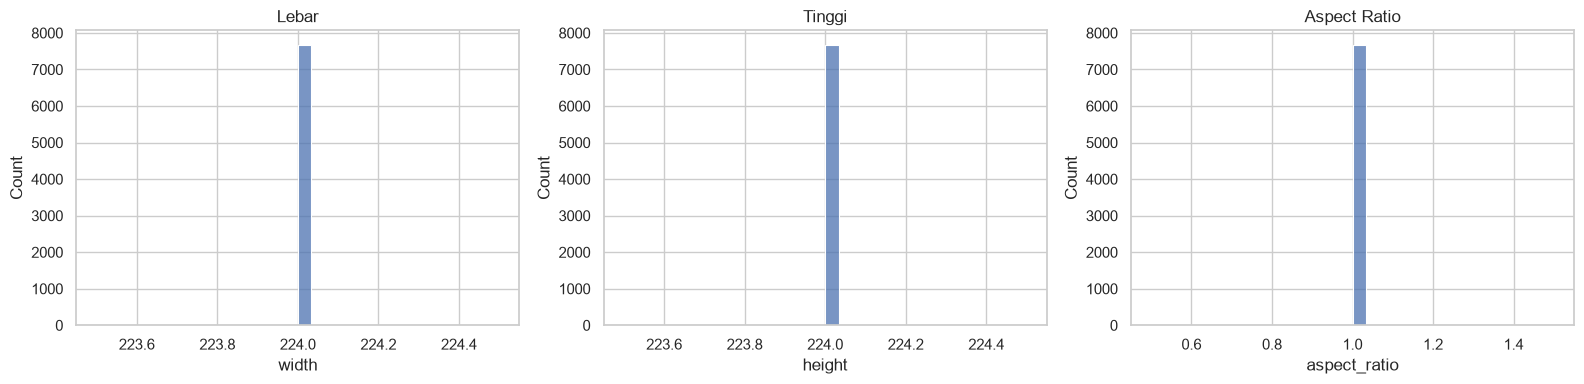

In [8]:
info, corrupt = [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            info.append({"path": p, "width": im.width, "height": im.height,
                         "mode": im.mode, "format": im.format,
                         "size_kb": os.path.getsize(p) / 1024})
    except Exception as e:
        corrupt.append((p, str(e)))

df = df.merge(pd.DataFrame(info), on="path", how="left")
df["aspect_ratio"] = df["width"] / df["height"]

print(f"Gambar rusak: {len(corrupt)}")
display(df[["width", "height", "aspect_ratio", "size_kb"]].describe())
print(df["mode"].value_counts(), "\n")
print(df["format"].value_counts(), "\n")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(5))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["width"], bins=30, ax=ax[0]).set(title="Lebar")
sns.histplot(df["height"], bins=30, ax=ax[1]).set(title="Tinggi")
sns.histplot(df["aspect_ratio"], bins=30, ax=ax[2]).set(title="Aspect Ratio")
plt.tight_layout(); plt.show()

In [9]:
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].apply(md5)
dup = df[df.duplicated("hash", keep=False)]
print(f"Gambar duplikat       : {len(dup)}")
print("Duplikat lintas kelas :", (dup.groupby("hash")["kelas"].nunique() > 1).sum())
print("Leakage antar split   :", (df.groupby("hash")["split"].nunique() > 1).sum())

Gambar duplikat       : 0
Duplikat lintas kelas : 0
Leakage antar split   : 0


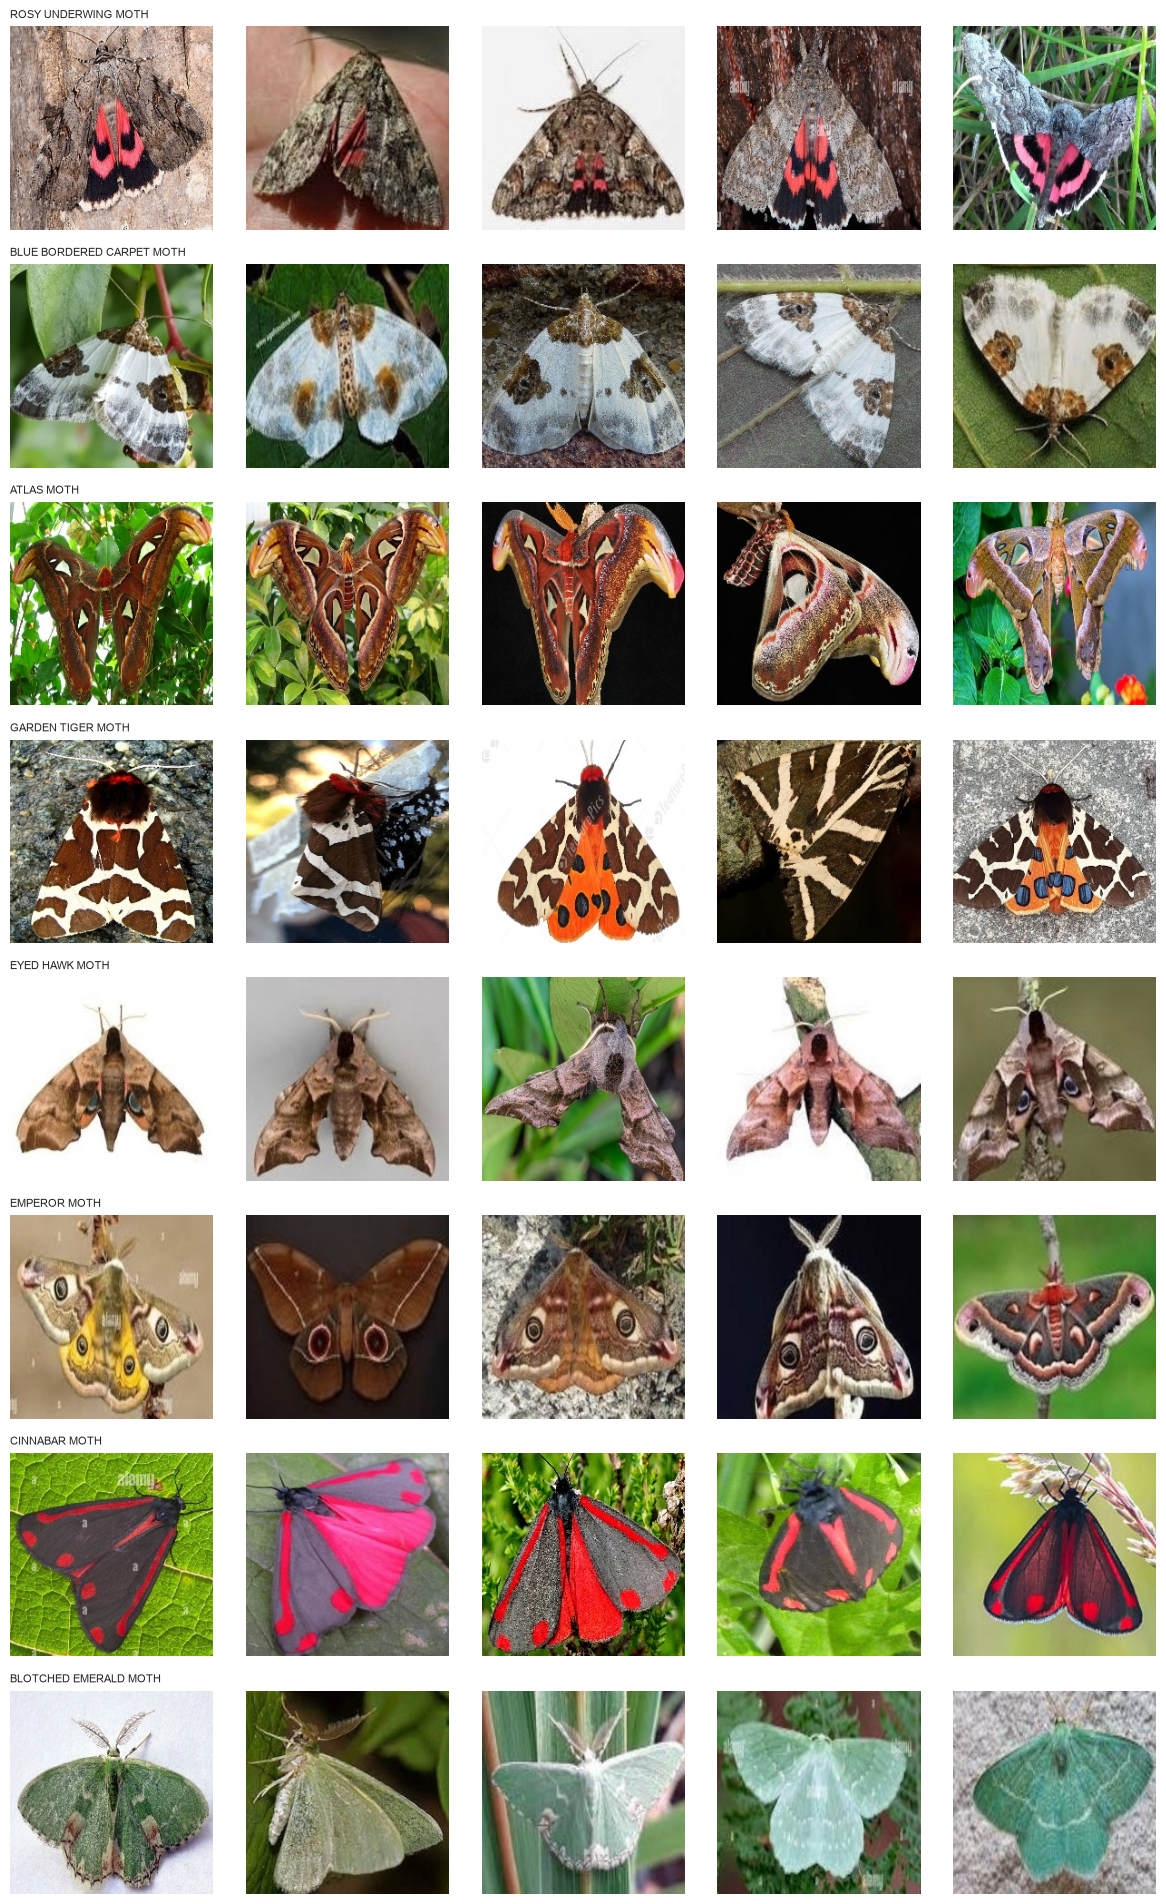

In [10]:
chosen = random.sample(list(df["kelas"].unique()), 8)
fig, axes = plt.subplots(len(chosen), 5, figsize=(12, len(chosen) * 2.4))
for i, cls in enumerate(chosen):
    paths = df[df["kelas"] == cls]["path"].sample(5, random_state=1)
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

Gambar dianalisis: 1500
Mean RGB (0-1) untuk normalisasi:
 R    0.523692
G    0.496530
B    0.394924
dtype: float32


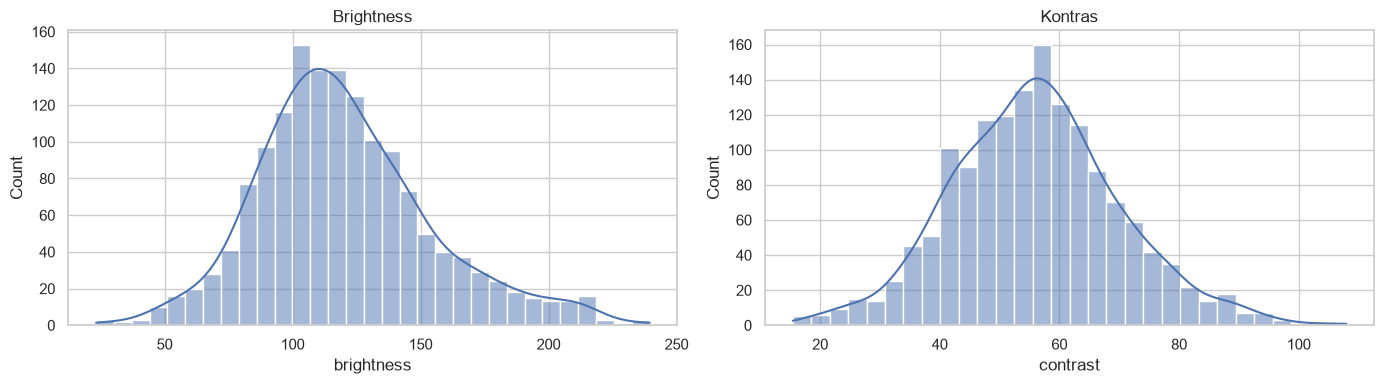

In [12]:
# ambil sampel per kelas tanpa groupby.apply
parts = []
for kelas, g in df.groupby("kelas"):
    parts.append(g.sample(min(len(g), SAMPLE_PER_CLASS), random_state=42))
sub = pd.concat(parts, ignore_index=True)

pix = []
for _, r in sub.iterrows():
    try:
        a = np.asarray(Image.open(r["path"]).convert("RGB").resize((128, 128)), dtype=np.float32)
    except Exception as e:
        print("Lewati:", r["path"], e)
        continue
    pix.append({"kelas": r["kelas"], "R": a[..., 0].mean(), "G": a[..., 1].mean(),
                "B": a[..., 2].mean(), "brightness": a.mean(), "contrast": a.std()})
pix = pd.DataFrame(pix)

print(f"Gambar dianalisis: {len(pix)}")
print("Mean RGB (0-1) untuk normalisasi:\n", pix[["R", "G", "B"]].mean() / 255)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pix["brightness"], kde=True, ax=ax[0]).set(title="Brightness")
sns.histplot(pix["contrast"], kde=True, ax=ax[1]).set(title="Kontras")
plt.tight_layout(); plt.show()

1. Kelas terbanyak   : JULY BELLE MOTH (196 gambar)
   Top 5:
kelas
JULY BELLE MOTH           196
BLAIRS MOCHA              187
KENTISH GLORY MOTH        185
LACE BORDER MOTH          185
PALPITA VITREALIS MOTH    184 

2. Kelas tersedikit  : SIXSPOT BURNET MOTH (111 gambar)
   Bottom 5:
kelas
BLOTCHED EMERALD MOTH        127
LUNA MOTH                    127
COMET MOTH                   115
PURPLE BORDERED GOLD MOTH    114
SIXSPOT BURNET MOTH          111 

3. Perbedaan antar kelas
   Selisih (max-min) : 85 gambar
   Rasio (max/min)   : 1.77
   Rata-rata         : 153.7
   Median            : 150.5
   Std deviasi       : 21.8
   Koef. variasi (CV): 14.2%

4. Kesimpulan keseimbangan
   Status: CUKUP SEIMBANG (imbalance ringan) (rasio 1.77)
   Kelas jauh di bawah rata-rata: 9
   Kelas jauh di atas rata-rata : 12


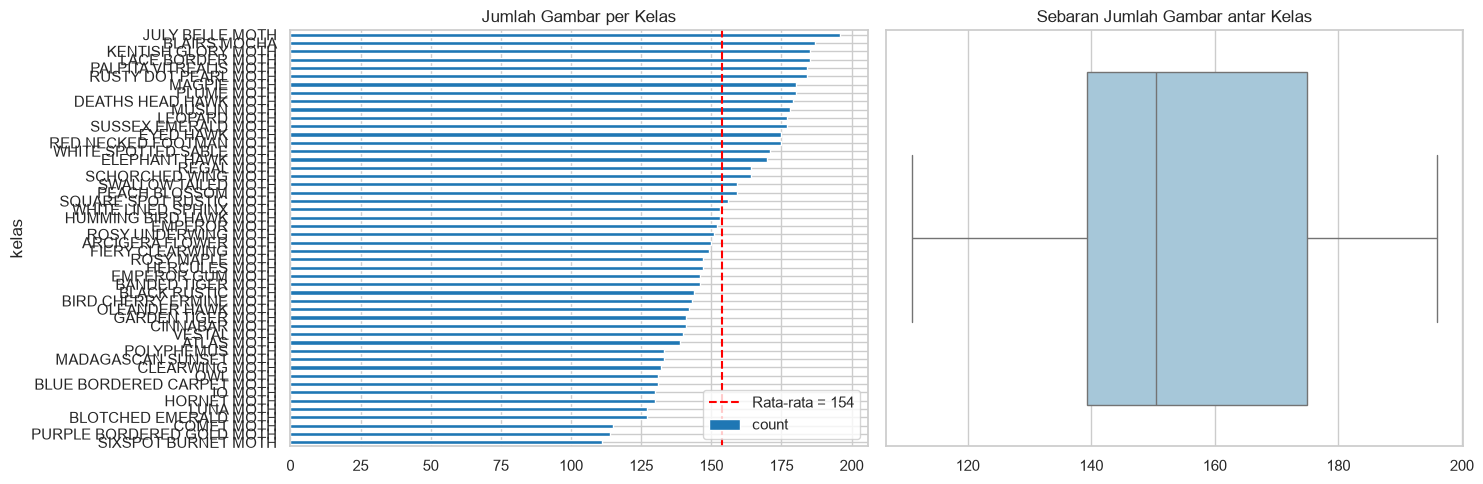

In [14]:
counts = df["kelas"].value_counts()

# 1. Kelas terbanyak
terbanyak = counts.idxmax()
print(f"1. Kelas terbanyak   : {terbanyak} ({counts.max()} gambar)")
print("   Top 5:")
print(counts.head(5).to_string(), "\n")

# 2. Kelas tersedikit
tersedikit = counts.idxmin()
print(f"2. Kelas tersedikit  : {tersedikit} ({counts.min()} gambar)")
print("   Bottom 5:")
print(counts.tail(5).to_string(), "\n")

# 3. Perbedaan jumlah antar kelas
selisih = counts.max() - counts.min()
rasio = counts.max() / counts.min()
print("3. Perbedaan antar kelas")
print(f"   Selisih (max-min) : {selisih} gambar")
print(f"   Rasio (max/min)   : {rasio:.2f}")
print(f"   Rata-rata         : {counts.mean():.1f}")
print(f"   Median            : {counts.median():.1f}")
print(f"   Std deviasi       : {counts.std():.1f}")
print(f"   Koef. variasi (CV): {counts.std() / counts.mean() * 100:.1f}%\n")

# 4. Seimbang atau tidak
print("4. Kesimpulan keseimbangan")
if rasio <= 1.5:
    status = "SEIMBANG"
elif rasio <= 3:
    status = "CUKUP SEIMBANG (imbalance ringan)"
else:
    status = "TIDAK SEIMBANG (imbalance signifikan)"
print(f"   Status: {status} (rasio {rasio:.2f})")

# kelas yang menyimpang jauh dari rata-rata (di luar ±1 std)
bawah = counts[counts < counts.mean() - counts.std()]
atas = counts[counts > counts.mean() + counts.std()]
print(f"   Kelas jauh di bawah rata-rata: {len(bawah)}")
print(f"   Kelas jauh di atas rata-rata : {len(atas)}")

# visualisasi
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
counts.sort_values().plot(kind="barh", ax=ax[0], color="#1f77b4")
ax[0].axvline(counts.mean(), color="red", ls="--", label=f"Rata-rata = {counts.mean():.0f}")
ax[0].set_title("Jumlah Gambar per Kelas"); ax[0].legend()
sns.boxplot(x=counts.values, ax=ax[1], color="#9ecae1")
ax[1].set_title("Sebaran Jumlah Gambar antar Kelas")
plt.tight_layout(); plt.show()

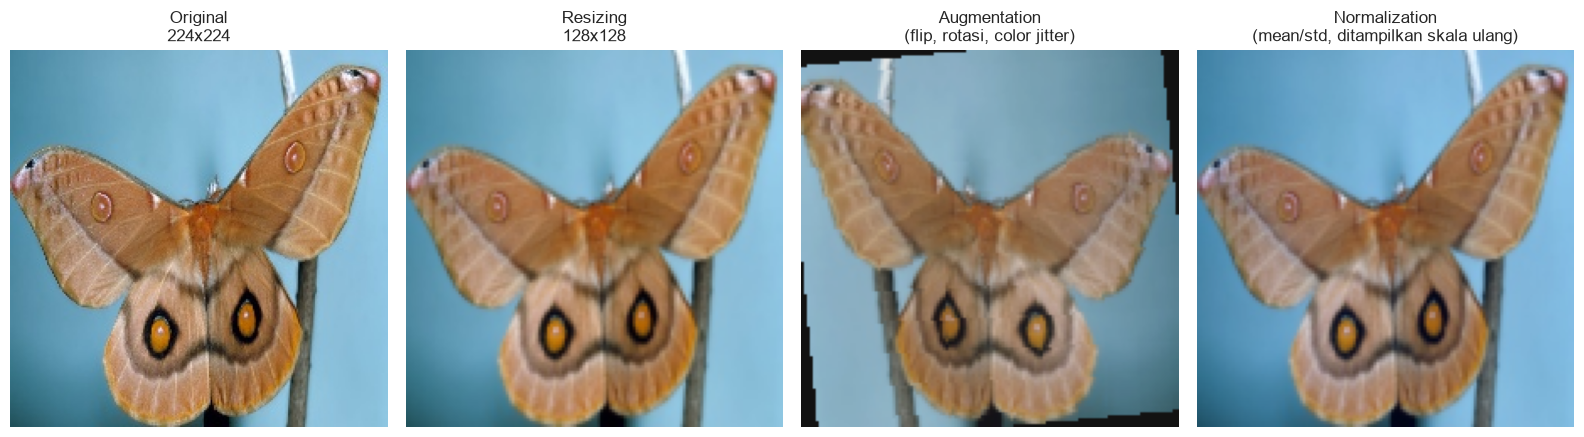

Bentuk tensor  : (128, 128, 3) (H, W, C)
Nilai min/max  : -2.12 / 2.64
Mean per channel: [0.211 0.503 0.649]


In [15]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

sys.path.append(str(Path("..").resolve()))     # supaya folder Utils/ terbaca dari notebooks/
from Utils.getData import getImageLabel, MEAN, STD

IMG_SIZE = 128
ds_plain = getImageLabel(folder=str(DATA_DIR / "train"), img_size=IMG_SIZE, augment=False)
ds_aug   = getImageLabel(folder=str(DATA_DIR / "train"), img_size=IMG_SIZE, augment=True)

def denorm(t):
    """tensor (H,W,C) ternormalisasi -> gambar 0-1 untuk ditampilkan"""
    return np.clip(t.numpy() * STD + MEAN, 0, 1)

idx = np.random.randint(len(ds_plain))
path, _ = ds_plain.dataset[idx]
original = Image.open(path).convert("RGB")
resized = original.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

x_norm, _ = ds_plain[idx]                      # hasil akhir yang masuk ke model
x_norm_vis = (x_norm.numpy() - x_norm.numpy().min()) / (x_norm.numpy().max() - x_norm.numpy().min())
x_aug, _ = ds_aug[idx]

fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
ax[0].imshow(original);      ax[0].set_title(f"Original\n{original.size[0]}x{original.size[1]}")
ax[1].imshow(resized);       ax[1].set_title(f"Resizing\n{IMG_SIZE}x{IMG_SIZE}")
ax[2].imshow(denorm(x_aug)); ax[2].set_title("Augmentation\n(flip, rotasi, color jitter)")
ax[3].imshow(x_norm_vis);    ax[3].set_title("Normalization\n(mean/std, ditampilkan skala ulang)")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("preprocessing_alur.png", dpi=200, bbox_inches="tight")
plt.show()

print("Bentuk tensor  :", tuple(x_norm.shape), "(H, W, C)")
print("Nilai min/max  :", round(x_norm.min().item(), 2), "/", round(x_norm.max().item(), 2))
print("Mean per channel:", x_norm.mean(dim=(0, 1)).numpy().round(3))

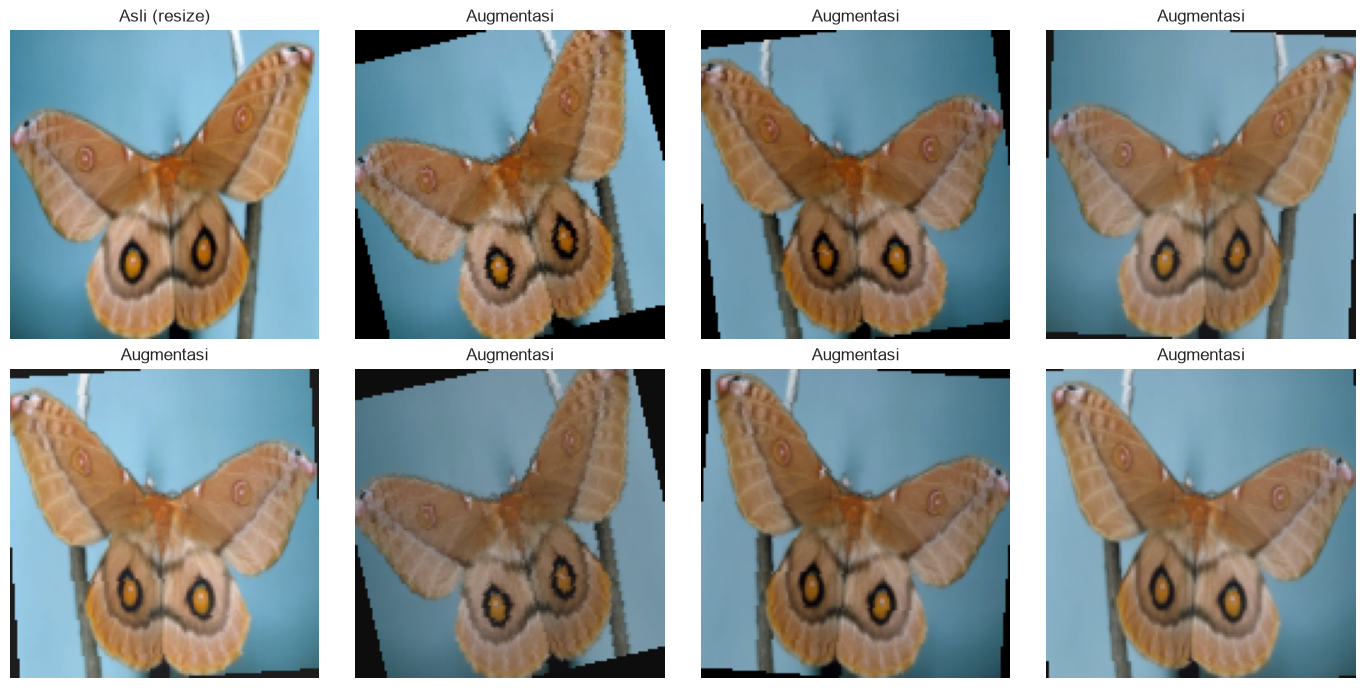

In [16]:
# variasi augmentasi dari satu gambar yang sama
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(resized); axes[0, 0].set_title("Asli (resize)")
for a in axes.flat[1:]:
    a.imshow(denorm(ds_aug[idx][0])); a.set_title("Augmentasi")
for a in axes.flat: a.axis("off")
plt.tight_layout()
plt.savefig("augmentasi_variasi.png", dpi=200, bbox_inches="tight")
plt.show()